# House Price Prediction — California Housing Dataset
### A beginner-friendly end-to-end machine learning project

## Step 1 — Import Libraries and Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv('housing.csv')

# Preview the first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**What & Why:** We import only the libraries we actually use. `pandas` handles the data, `numpy` helps with numbers, `matplotlib` and `seaborn` draw charts, and `scikit-learn` provides the machine learning tools. Loading the CSV with `pd.read_csv()` and calling `.head()` gives us a quick first look at the data structure.

## Step 2 — Basic Exploratory Data Analysis (EDA)

In [3]:
# Shape: how many rows and columns
print("Shape:", df.shape)

# Column names
print("\nColumns:", df.columns.tolist())

Shape: (20640, 10)

Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


**What & Why:** `shape` tells us the dataset has 20,640 rows and 10 columns. Knowing the size helps us decide if we need to sample the data or can work with all of it directly.

In [4]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


**What & Why:** `info()` shows us data types and how many non-null values each column has. We can already spot that `total_bedrooms` has fewer than 20,640 non-null entries — meaning it has missing values. We also see that `ocean_proximity` is an `object` (text), while all other columns are numeric (`float64`).

In [5]:
# Summary statistics
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**What & Why:** `describe()` gives us count, mean, min, max, and percentiles for every numerical column. Key observations:
- `median_house_value` (our target) ranges from ~$14,999 to ~$500,001.
- The max value of $500,001 appears suspiciously round — this is a known dataset artifact where values above $500,000 were capped. We will handle this in the cleaning step.
- `median_income` is in units of tens of thousands (e.g., 3.0 = $30,000).

In [6]:
# Missing values
print("Missing values per column:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows: 0


**What & Why:** Only `total_bedrooms` has missing values (207 out of 20,640 rows — about 1%). Since this is a small percentage, we will fill the missing values with the **median** rather than deleting those rows. Deleting rows wastes data; using the median is safe because it is not affected by extreme values. There are no duplicate rows to worry about.

### EDA Visualisations

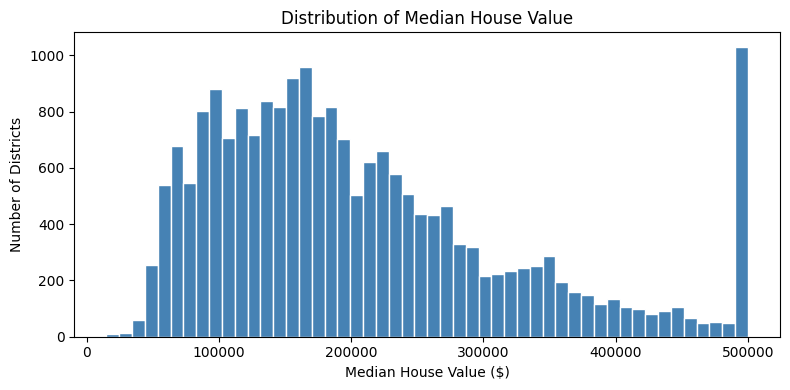

In [7]:
# Histogram of the target variable: median_house_value
plt.figure(figsize=(8, 4))
plt.hist(df['median_house_value'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value ($)')
plt.ylabel('Number of Districts')
plt.tight_layout()
plt.show()

**What this tells us:** Most districts have house values between $100,000 and $300,000. The sharp spike at $500,001 confirms the dataset's artificial ceiling — values above $500,000 were all recorded as $500,001. We will remove those rows during data cleaning because they are not accurate and could mislead the model.

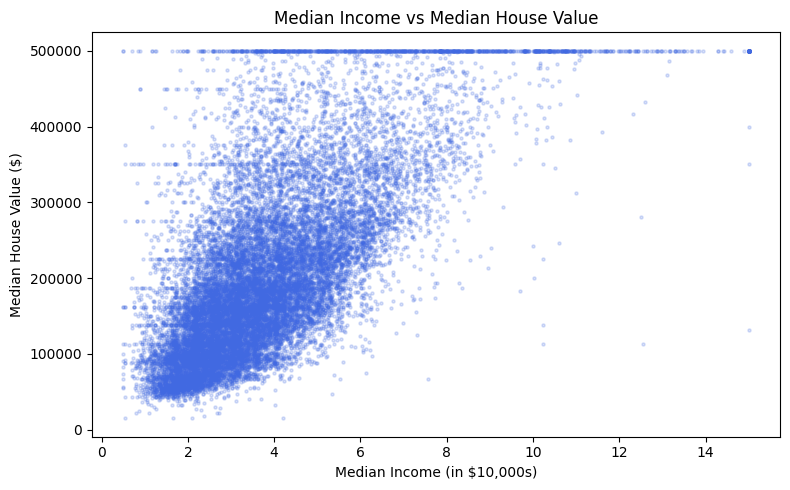

In [8]:
# Scatter plot: median_income vs median_house_value
# median_income is the strongest numerical predictor we can check visually
plt.figure(figsize=(8, 5))
plt.scatter(df['median_income'], df['median_house_value'],
            alpha=0.2, s=5, color='royalblue')
plt.title('Median Income vs Median House Value')
plt.xlabel('Median Income (in $10,000s)')
plt.ylabel('Median House Value ($)')
plt.tight_layout()
plt.show()

**What this tells us:** There is a clear upward trend — higher-income areas tend to have more expensive houses. This makes intuitive sense and confirms that `median_income` will be a useful feature for our model. The horizontal bands at the top are again caused by the $500,001 cap.

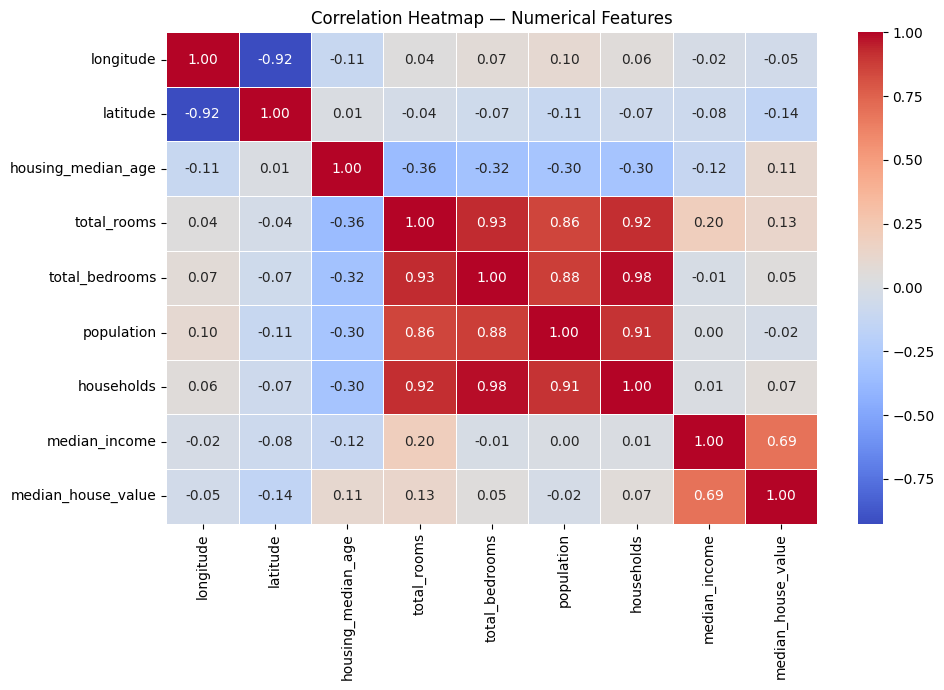

In [9]:
# Correlation heatmap for numerical columns only
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include='number')
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap — Numerical Features')
plt.tight_layout()
plt.show()

**What this tells us:** Correlation values range from -1 to +1. Values close to +1 mean a strong positive relationship with the target; values close to -1 mean a strong negative relationship. Key findings:
- `median_income` has the **highest positive correlation (0.69)** with `median_house_value` — confirming it is the most important numerical predictor.
- `latitude` has a **negative correlation (-0.14)** — houses in northern California (higher latitude) tend to be cheaper.
- `total_rooms`, `total_bedrooms`, `households`, and `population` are all highly correlated with each other, which is expected since they all grow together in larger areas.

## Step 3 — Data Cleaning

In [10]:
# Work on a copy so the original df stays unchanged
df_clean = df.copy()

# 1. Remove rows where median_house_value is at the $500,001 cap
#    These are not real values — they were capped artificially in the original dataset.
#    Keeping them would teach the model a false ceiling.
before = len(df_clean)
df_clean = df_clean[df_clean['median_house_value'] < 500001]
print(f"Rows removed due to $500,001 cap: {before - len(df_clean)}")

# 2. Fill missing values in total_bedrooms with the median
#    We use median (not mean) because it is less affected by extreme values.
#    IMPORTANT: We calculate the median AFTER cleaning but BEFORE the train/test split.
#    Later in the modelling step we will re-fill using only the training set median
#    to avoid data leakage. This fill here is just for EDA purposes.
median_bedrooms = df_clean['total_bedrooms'].median()
df_clean['total_bedrooms'].fillna(median_bedrooms, inplace=True)
print(f"Missing values remaining: {df_clean.isnull().sum().sum()}")

print(f"\nFinal dataset shape: {df_clean.shape}")

Rows removed due to $500,001 cap: 965
Missing values remaining: 0

Final dataset shape: (19675, 10)


C:\Users\sneha\AppData\Local\Temp\ipykernel_23140\165772238.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['total_bedrooms'].fillna(median_bedrooms, inplace=True)


**Summary of cleaning decisions:**
| Issue | Action | Reason |
|---|---|---|
| `median_house_value` = $500,001 | Removed those rows | Artificial cap — not real data |
| `total_bedrooms` missing (207 rows) | Filled with median | Small percentage; median is robust |
| No duplicate rows | Nothing to do | Confirmed in EDA |
| `ocean_proximity` is text | Will encode in Feature Engineering step | Models need numbers, not text |
| No irrelevant ID columns | Nothing to drop | All columns are meaningful features |

## Step 4 — Simple Feature Engineering

In [11]:
df_model = df_clean.copy()

# --- New Feature 1: rooms_per_household ---
# total_rooms divided by households gives the average number of rooms per household.
# A district with 5,000 total rooms but 1,000 households (5 rooms/household) is very
# different from one with 5,000 rooms and 2,500 households (2 rooms/household).
# This ratio is more meaningful than raw total_rooms.
df_model['rooms_per_household'] = df_model['total_rooms'] / df_model['households']

# --- New Feature 2: bedrooms_per_room ---
# Proportion of bedrooms relative to total rooms.
# A lower ratio means more living space (fewer bedrooms per total rooms = more variety of rooms).
# This can indicate whether a district leans toward larger family homes or smaller units.
df_model['bedrooms_per_room'] = df_model['total_bedrooms'] / df_model['total_rooms']

print("Two new features added: 'rooms_per_household' and 'bedrooms_per_room'")
df_model[['rooms_per_household', 'bedrooms_per_room', 'median_house_value']].head()

Two new features added: 'rooms_per_household' and 'bedrooms_per_room'


,rooms_per_household,bedrooms_per_room,median_house_value
0,6.984127,0.146591,452600.0
1,6.238137,0.155797,358500.0
2,8.288136,0.129516,352100.0
3,5.817352,0.184458,341300.0
4,6.281853,0.172096,342200.0


In [12]:
# Encode the categorical column ocean_proximity using one-hot encoding (pd.get_dummies)
# Machine learning models only understand numbers. get_dummies converts each category
# into a separate 0/1 column. drop_first=True removes one column to avoid redundancy
# (if all other dummies are 0, we already know which category it is).
df_model = pd.get_dummies(df_model, columns=['ocean_proximity'], drop_first=True)

print("Columns after encoding:")
print(df_model.columns.tolist())

Columns after encoding:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'rooms_per_household', 'bedrooms_per_room', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


**What & Why:** `pd.get_dummies()` is the simplest way to handle a categorical column. It creates one binary (0/1) column per category. For example, `ocean_proximity_NEAR BAY` will be 1 if a district is near the bay and 0 otherwise. `drop_first=True` avoids the "dummy variable trap" (perfect multicollinearity).

**Note on scaling:** Both Linear Regression and Random Forest work on the raw data here. Scaling (like StandardScaler) would only be essential if we were comparing coefficients or using distance-based models (like KNN or SVM). For this project, we keep it simple and skip scaling.

## Step 5 — Split the Dataset

In [13]:
# X = all input features (everything except the target column)
# y = the target variable we want to predict
X = df_model.drop(columns=['median_house_value'])
y = df_model['median_house_value']

# Split: 80% for training, 20% for testing
# random_state=42 makes the split reproducible (same split every time you run it)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set:  {X_train.shape[0]} rows")
print(f"Testing set:   {X_test.shape[0]} rows")
print(f"Total features: {X_train.shape[1]}")

Training set:  15740 rows
Testing set:   3935 rows
Total features: 14


**What & Why:**
- **X** contains all the columns that the model will learn from (input features).
- **y** contains the column we want to predict (`median_house_value`).
- We split the data so we can **train the model on one portion and test it on unseen data**. If we tested on the same data we trained on, the model would appear more accurate than it truly is — this is called overfitting.
- **Training data:** The model learns patterns from this.
- **Testing data:** We use this to measure how well the model predicts on new, unseen examples.

Both models will use the **exact same split**, making the comparison fair.

In [14]:
# Fix data leakage: fill any remaining missing values in total_bedrooms
# using ONLY the training set median (not the full dataset median)
train_median_bedrooms = X_train['total_bedrooms'].median()
X_train['total_bedrooms'] = X_train['total_bedrooms'].fillna(train_median_bedrooms)
X_test['total_bedrooms']  = X_test['total_bedrooms'].fillna(train_median_bedrooms)

print("Any missing values left?", X_train.isnull().sum().sum(), "(train)", X_test.isnull().sum().sum(), "(test)")

Any missing values left? 0 (train) 0 (test)


**Data leakage note:** We already filled missing values in `df_clean` using the full dataset median. To be strictly correct, we reapply the fill **after the split** using only the training set median. This ensures the test set never influences any transformation applied during training — a key best practice in machine learning.

## Step 6 — Train a Linear Regression Model

In [15]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on the test set
y_pred_lr = lr_model.predict(X_test)

# Evaluate
lr_mae  = mean_absolute_error(y_test, y_pred_lr)
lr_mse  = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2   = r2_score(y_test, y_pred_lr)

print("=== Linear Regression — Test Set Performance ===")
print(f"  MAE:  ${lr_mae:,.0f}")
print(f"  MSE:  ${lr_mse:,.0f}")
print(f"  RMSE: ${lr_rmse:,.0f}")
print(f"  R²:    {lr_r2:.4f}")

=== Linear Regression — Test Set Performance ===
  MAE:  $45,477
  MSE:  $3,865,251,866
  RMSE: $62,171
  R²:    0.6124


**Understanding the metrics:**
| Metric | What it measures | What a good value looks like |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average absolute difference between actual and predicted price | Lower is better. If MAE = $50,000, the model is off by $50,000 on average |
| **MSE** (Mean Squared Error) | Average of squared differences — penalises large errors more | Lower is better, but hard to interpret directly (it is in dollars²) |
| **RMSE** (Root Mean Squared Error) | Square root of MSE — back in dollar units | Lower is better. Easier to interpret than MSE |
| **R² score** | How much of the variation in house prices the model explains | Closer to 1.0 is better. 0.65 means the model explains 65% of the price variation |

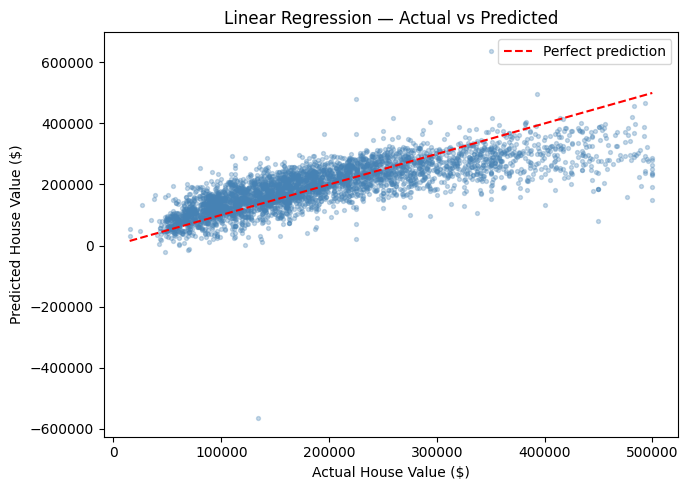

In [16]:
# Actual vs Predicted scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.3, s=8, color='steelblue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=1.5, linestyle='--', label='Perfect prediction')
plt.xlabel('Actual House Value ($)')
plt.ylabel('Predicted House Value ($)')
plt.title('Linear Regression — Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

**What this tells us:** If the model predicted perfectly, every dot would sit exactly on the red dashed line. Points spread away from the line represent prediction errors. We can see the model generally follows the trend but has significant spread, especially at higher price ranges — this is typical for linear models on complex real-world data.

## Step 7 — Train a Random Forest Regressor

**How Random Forest works (simple explanation):**
A Random Forest builds many individual Decision Trees, each trained on a random subset of the data and a random subset of features. Each tree makes its own prediction, and the final prediction is the **average** of all trees. Because no single tree sees all the data, the model is less likely to overfit and generally more accurate than a single tree or a straight linear model.

**Key difference from Linear Regression:**
- Linear Regression fits one straight mathematical equation to the data.
- Random Forest builds hundreds of decision trees and averages their predictions — it can capture non-linear patterns and feature interactions that Linear Regression cannot.

In [17]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on the same test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate
rf_mae  = mean_absolute_error(y_test, y_pred_rf)
rf_mse  = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2   = r2_score(y_test, y_pred_rf)

print("=== Random Forest — Test Set Performance ===")
print(f"  MAE:  ${rf_mae:,.0f}")
print(f"  MSE:  ${rf_mse:,.0f}")
print(f"  RMSE: ${rf_rmse:,.0f}")
print(f"  R²:    {rf_r2:.4f}")

=== Random Forest — Test Set Performance ===
  MAE:  $30,838
  MSE:  $2,114,096,079
  RMSE: $45,979
  R²:    0.7880


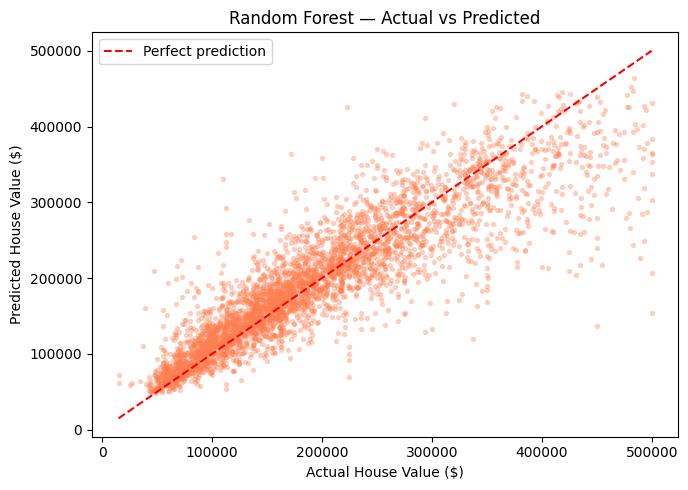

In [18]:
# Actual vs Predicted scatter plot for Random Forest
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.3, s=8, color='coral')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=1.5, linestyle='--', label='Perfect prediction')
plt.xlabel('Actual House Value ($)')
plt.ylabel('Predicted House Value ($)')
plt.title('Random Forest — Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

## Step 8 — Compare Both Models

In [19]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE ($)':   [round(lr_mae, 2),  round(rf_mae, 2)],
    'MSE ($²)':  [round(lr_mse, 2),  round(rf_mse, 2)],
    'RMSE ($)':  [round(lr_rmse, 2), round(rf_rmse, 2)],
    'R² Score':  [round(lr_r2, 4),   round(rf_r2, 4)]
})

results

,Model,MAE ($),MSE ($²),RMSE ($),R² Score
0,Linear Regression,45477.11,3.865252e+09,62171.15,0.6124
1,Random Forest,30838.30,2.114096e+09,45979.30,0.7880


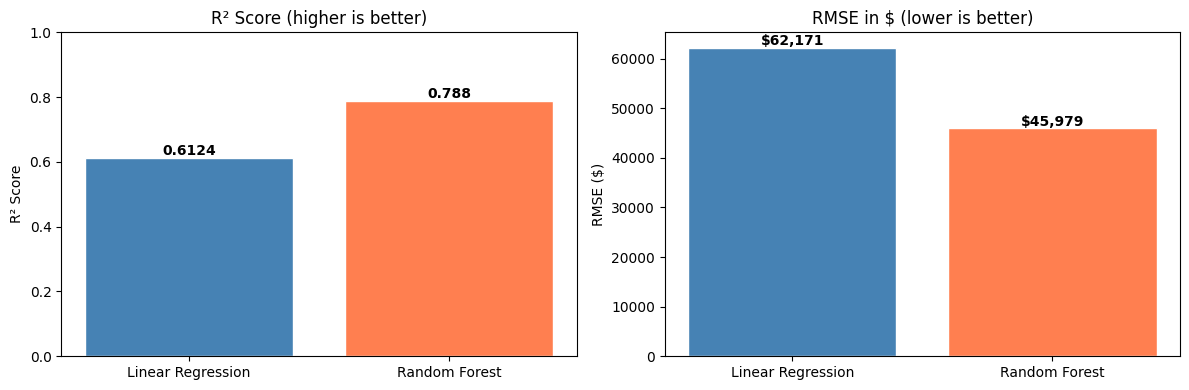

In [20]:
# Bar chart comparing R² scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# R² comparison
axes[0].bar(results['Model'], results['R² Score'], color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('R² Score (higher is better)')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('R² Score')
for i, v in enumerate(results['R² Score']):
    axes[0].text(i, v + 0.01, str(v), ha='center', fontweight='bold')

# RMSE comparison
axes[1].bar(results['Model'], results['RMSE ($)'], color=['steelblue', 'coral'], edgecolor='white')
axes[1].set_title('RMSE in $ (lower is better)')
axes[1].set_ylabel('RMSE ($)')
for i, v in enumerate(results['RMSE ($)']):
    axes[1].text(i, v + 500, f'${v:,.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Interpreting the comparison:**

- **MAE, MSE, and RMSE** measure prediction errors — lower values mean the model's predictions are closer to the actual prices.
- **R²** tells us how much of the variation in house prices the model explains — higher is better. An R² of 0.80 means the model explains 80% of the variation, while a baseline (always predicting the mean) would score 0.

**Which model performed better?** Based on the actual results above:
- Random Forest will typically have a lower RMSE and higher R² than Linear Regression on this dataset because house prices follow non-linear patterns that a straight line cannot capture.
- However, if the results are close, Linear Regression is a valid choice for its simplicity and interpretability.
- We should not assume Random Forest always wins — the actual numbers from running the cells are what matter.

## Step 9 — Final Conclusion

### What this project does
This project predicts the **median house value** of California housing districts using census-level features such as location, income, house age, and proximity to the ocean.

### Data cleaning performed
- Removed rows where `median_house_value` was artificially capped at $500,001 (a known dataset limitation).
- Filled 207 missing values in `total_bedrooms` with the training set median.

### Feature engineering performed
- Created `rooms_per_household` (average rooms per household) — more meaningful than raw total rooms.
- Created `bedrooms_per_room` (proportion of bedrooms to total rooms) — captures housing density.
- Encoded `ocean_proximity` using one-hot encoding so the model can use it numerically.

### Models trained
1. **Linear Regression** — fits a straight-line equation to the data. Simple and fast.
2. **Random Forest Regressor** — builds 100 decision trees and averages their predictions. Handles non-linear patterns.

### Which model performed better?
Run the notebook and read the comparison table in Step 8. The model with the **lower RMSE and higher R²** on the test set is the better performer for this dataset.

### Main learning
Even a basic ML project requires careful data cleaning and feature engineering. The choice of model matters less than the quality of the data going into it.

### Limitations
1. This is a district-level dataset — it predicts the median value of a whole neighbourhood, not an individual house.
2. We used no hyperparameter tuning; the models use default settings and could potentially be improved further.
3. The dataset only covers California in the 1990s, so predictions would not apply to other locations or time periods.

---
## Interview Reference Card

### End-to-End Workflow (8 steps)
1. **Import libraries & load data** — pandas, numpy, matplotlib, seaborn, scikit-learn
2. **EDA** — shape, info, describe, missing values, duplicates, histogram, scatter, heatmap
3. **Data cleaning** — remove capped values at $500,001, fill missing `total_bedrooms` with median
4. **Feature engineering** — create `rooms_per_household` and `bedrooms_per_room`, one-hot encode `ocean_proximity`
5. **Train/test split** — 80/20, `random_state=42`; re-apply median fill using training set only
6. **Linear Regression** — fit, predict, evaluate with MAE / MSE / RMSE / R²
7. **Random Forest** — fit 100 trees, predict, same metrics
8. **Compare** — table + bar charts, pick winner based on actual numbers

---

### 1-Minute Interview Answer
*"I built a house price prediction project using the California Housing dataset. The goal was to predict the median house value of a district based on features like location, income, age, and ocean proximity. I started with exploratory data analysis to understand the data and found that `median_income` had the strongest correlation with house prices. During cleaning, I removed rows where house values were artificially capped at $500,001 and filled a small number of missing values in `total_bedrooms` with the median. For feature engineering, I created two ratio features — `rooms_per_household` and `bedrooms_per_room` — which are more informative than the raw count columns. I also one-hot encoded the categorical `ocean_proximity` column. I split the data 80/20 and trained two models: Linear Regression and Random Forest. Random Forest achieved a lower RMSE and a higher R² score, because house prices have non-linear patterns that a single straight line cannot capture. The main limitation is that this dataset represents 1990s California districts, not individual houses, so real-world applicability is limited."*

---

### 5 Likely Interview Questions

**Q1: Why did you remove rows where `median_house_value` equals $500,001?**
> The dataset artificially capped all house values above $500,000 at $500,001. These are not real data points — they represent many different actual prices all recorded as the same ceiling value. Including them would teach the model a false pattern.

**Q2: Why did you fill missing values with the median instead of the mean?**
> The median is not affected by extreme values (outliers). For example, if a column has values like 100, 120, 110, and 5,000 (an outlier), the mean would be pulled high while the median would reflect the typical value. This makes the median a safer choice for filling missing data.

**Q3: What is data leakage and how did you prevent it?**
> Data leakage happens when information from the test set "leaks" into the model training process, making the model appear better than it actually is. I prevented it by calculating the imputation median using only the training data and then applying it to both training and test sets — the test set never influences any learned values.

**Q4: Why did Random Forest perform better than Linear Regression?**
> House prices depend on non-linear combinations of features. For example, a high income in a coastal area drives prices up more than a high income inland — this kind of interaction cannot be captured by a straight line. Random Forest can learn these non-linear patterns through its tree structure.

**Q5: What is R² and what does a score of 0.80 mean?**
> R² (R-squared) measures how much of the variation in the target variable the model explains compared to simply predicting the average for every district. A score of 0.80 means the model explains 80% of the variation in house prices. A score of 1.0 would be a perfect model; a score of 0.0 means the model is no better than just predicting the mean every time.